# 04 · Time-Series Preparation

Turn transactions into a clean daily demand series, understand trend/seasonality/autocorrelation, and define the train / holdout split used by every forecasting model.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. Daily demand series (units) - gaps filled with zeros

2024-01-01 -> 2025-12-31 | days: 731 | missing days: 0


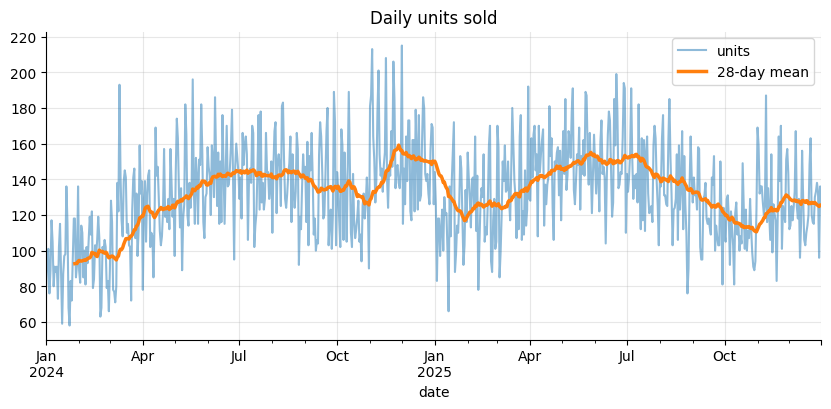

In [2]:
series = daily.set_index("date")["units"].astype(float)
print(series.index.min().date(), "->", series.index.max().date(), "| days:", len(series), "| missing days:", series.index.to_series().diff().dropna().ne(pd.Timedelta(days=1)).sum())
series.plot(title="Daily units sold", alpha=.5); series.rolling(28).mean().plot(lw=2.5, label="28-day mean"); plt.legend(); plt.show()

## 2. Decomposition (trend, weekly pattern, residual)

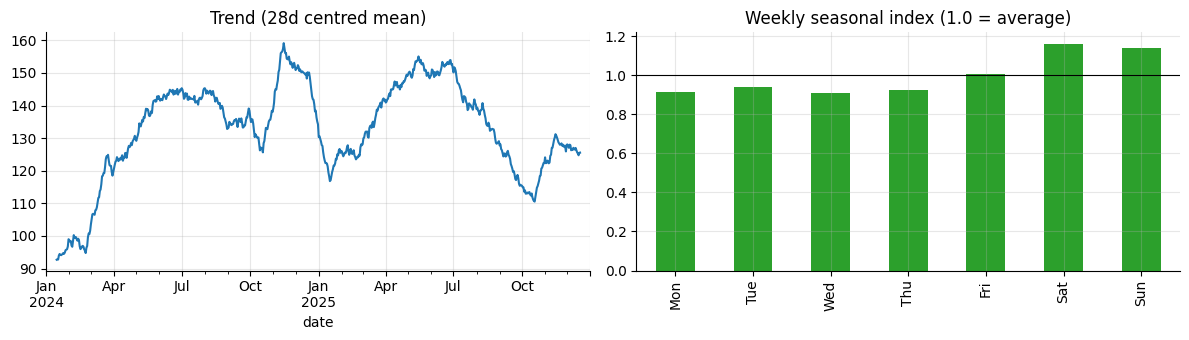

In [3]:
trend = series.rolling(28, center=True).mean()
detr = series / trend
weekly = detr.groupby(series.index.dayofweek).mean()
weekly.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
trend.plot(ax=ax[0], title="Trend (28d centred mean)")
weekly.plot.bar(ax=ax[1], title="Weekly seasonal index (1.0 = average)", color="C2"); ax[1].axhline(1, c="k", lw=.8)
plt.tight_layout(); plt.show()

## 3. Autocorrelation - strong weekly (lag 7) memory justifies lag features

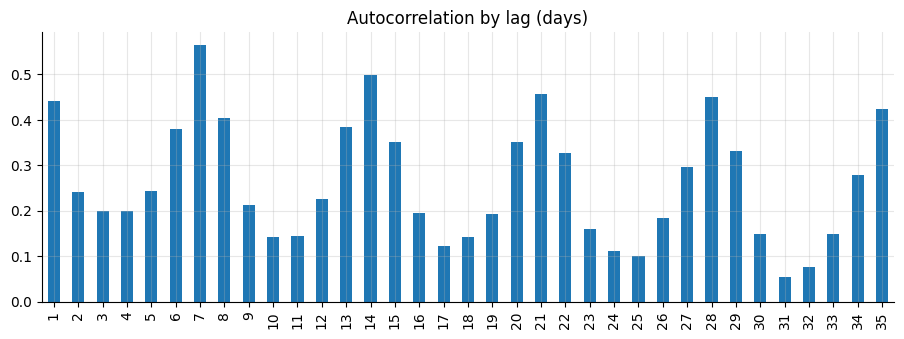

{1: np.float64(0.441), 7: np.float64(0.565), 14: np.float64(0.498), 28: np.float64(0.451)}


In [4]:
ac = pd.Series({lag: series.autocorr(lag) for lag in range(1, 36)})
ac.plot.bar(title="Autocorrelation by lag (days)", figsize=(11, 3.5)); plt.show()
print({l: round(ac[l], 3) for l in (1, 7, 14, 28)})

## 4. Train / holdout split
The last 60 days (which include the Nov-Dec peak) are held out: a deliberately hard test.

train: 2024-01-01 -> 2025-11-01 (671 days)
test : 2025-11-02 -> 2025-12-31 (60 days)


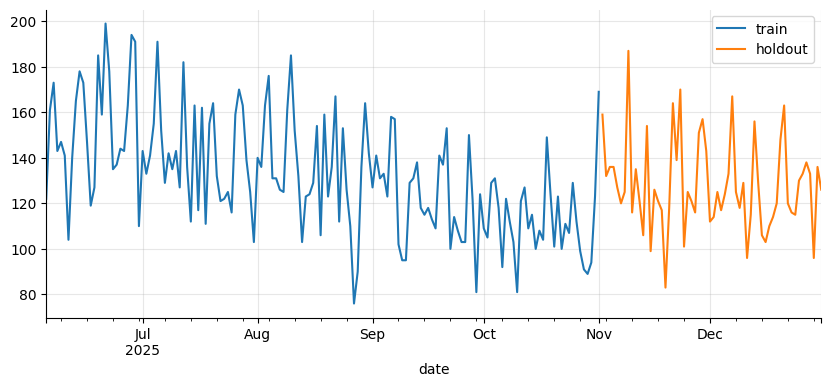

In [5]:
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]
print(f"train: {train.index.min().date()} -> {train.index.max().date()} ({len(train)} days)")
print(f"test : {test.index.min().date()} -> {test.index.max().date()} ({len(test)} days)")
ax = train.tail(150).plot(label="train"); test.plot(ax=ax, label="holdout"); plt.legend(); plt.show()

## 5. Supervised feature frame for the GBM
Lags and rolling means are expressed relative to the trailing 28-day level, so the model learns *shape* rather than absolute size.

In [6]:
from src.forecasting.features import build_feature_frame
X, level = build_feature_frame(series)
X.dropna().head()

,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_std_7,level,dow,is_weekend,month,holiday_season,doy_sin,doy_cos
date,,,,,,,,,,,,,
2024-01-29,1.272727,0.733436,0.927581,0.873652,0.944530,0.258399,92.714286,0,0,1,0,0.478434,0.878124
2024-01-30,0.915385,0.624615,0.635385,1.023077,0.969231,0.241849,92.857143,1,0,1,0,0.493468,0.869764
2024-01-31,0.991914,0.894879,0.938005,1.088949,1.022719,0.188852,92.750000,2,0,1,0,0.508356,0.861147
2024-02-01,1.446809,0.765957,1.031915,0.808511,1.089666,0.237551,94.000000,3,0,2,0,0.523094,0.852275
2024-02-02,0.942155,1.016257,1.037429,0.942155,1.110019,0.202930,94.464286,4,0,2,0,0.537677,0.843151
